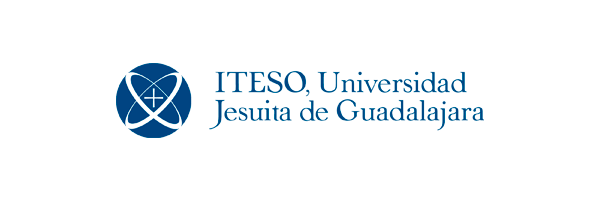

# Reporte de Prácticas de Perceptrón Multicapa (Regresión)

## Tarea 8

**Integrantes:**

- Valeria Esmer Lobo

- Dayanni Godoy Rosales

- Estephany Lisset Herrera Placencia

- Maria Fernanda Vargas Vaca

**Fecha:** 27 de noviembre de 2026

**Institución:** Instituto Tecnológico y de Estudios Superiores de Occidente (ITESO)

**Materia:** Métodos de Inteligencia Artificial

## Índice

1. [Introducción y objetivos](#introduccion)
2. [Práctica 1: predicción de un paso](#practica1)
    - 2.1 [Definición del problema](#p1-definicion)
    - 2.2 [Descripción del algoritmo](#p1-algoritmo)
    - 2.3 [Implementación](#p1-implementacion)
    - 2.4 [Pruebas y resultados](#p1-pruebas)
    - 2.5 [Análisis y conclusiones de la práctica](#p1-analisis)
3. [Práctica 2: predicción multihorizonte con datos normalizados](#practica2)
    - 3.1 [Definición del problema](#p2-definicion)
    - 3.2 [Descripción del algoritmo](#p2-algoritmo)
    - 3.3 [Implementación](#p2-implementacion)
    - 3.4 [Pruebas y resultados](#p2-pruebas)
    - 3.5 [Análisis y conclusiones de la práctica](#p2-analisis)
4. [Conclusiones](#conclusiones)
    - 4.1 [Conclusiones personales](#conclusiones-personales)
    - 4.2 [Conclusiones generales](#conclusiones-generales)

<a id="introduccion"></a>

## 1. Introducción y objetivos

En la tarea anterior trabajamos con redes competitivas, que aprenden **sin supervisión**. En esta tarea regresamos al **aprendizaje supervisado**, pero con una red más completa que el perceptrón simple y ADALINE: el **perceptrón multicapa** (MLP, *Multilayer Perceptron*).

Un MLP tiene una **capa de entrada**, una o más **capas ocultas** y una **capa de salida**. Cada neurona hace una suma ponderada de sus entradas, le suma un sesgo y le aplica una **función de activación**. Las capas ocultas con activaciones no lineales permiten que la red aprenda relaciones que no son líneas rectas, algo que un perceptrón de una sola capa no puede hacer. Los pesos se ajustan con la **retropropagación del error** (*backpropagation*): la red compara su predicción con el valor real, calcula el error y lo manda hacia atrás, capa por capa, para saber cuánto debe cambiar cada peso.

En las dos prácticas el MLP se usa para **regresión**, es decir, para predecir un número y no una clase. El problema es estimar el precio de un activo de la Bolsa Mexicana de Valores a partir de sus precios anteriores. Para eso la serie de tiempo se convierte en una tabla de entradas y salidas usando **rezagos**: si conocemos los últimos $p$ precios, la red aprende a estimar el que sigue,

$$\hat{y}(t) = f\big(y(t-1),\, y(t-2),\, \dots,\, y(t-p)\big)$$

donde $f$ es la función que aprende el MLP. En la **Práctica 1** la red predice **un solo valor** (el día siguiente). En la **Práctica 2** predice **cinco valores a la vez** (varios días hacia adelante) y trabaja con **datos normalizados**.

**Objetivo general:** implementar perceptrones multicapa de regresión para predecir el precio de un activo de la BMV a partir de sus valores pasados, y evaluar qué tan buenas son sus predicciones con datos que la red no vio durante el entrenamiento.

**Objetivos específicos**
- Transformar una serie de tiempo en un problema supervisado con una matriz de rezagos.
- Entrenar un MLP con `MLPRegressor` de scikit-learn para predecir el precio del día siguiente (Práctica 1).
- Comparar arquitecturas, números de rezagos y funciones de activación, y contrastar los resultados con un modelo ingenuo de referencia.
- Extender el modelo para predecir cinco días hacia adelante con una sola red de cinco salidas (Práctica 2).
- Analizar el efecto de normalizar los datos y revisar la curva de pérdida durante el entrenamiento.
- Medir el desempeño con el 10 % final de la serie, que se reserva como conjunto de prueba.

<a id="practica1"></a>

## 2. Práctica 1: predicción de un paso

<a id="p1-definicion"></a>

### 2.1 Definición del problema

El archivo `Datos_BMV.csv` (sin encabezado) guarda los precios diarios de 35 activos de la BMV. Se toma la columna con **índice 10** en Python (columna 11 del archivo, activo BMV_11), que tiene **774 observaciones** con precios entre 16.53 y 20.02.

Se quiere predecir el **precio del día siguiente** usando los precios de los $n_{rez}$ días anteriores. Es un problema de **regresión supervisada**: cada fila de la matriz de rezagos trae sus entradas y la respuesta correcta. Se busca:

1. Construir la matriz de rezagos: las entradas son $y(t-1), \dots, y(t-n_{rez})$ y la salida es $y(t)$. Con $n_{rez}=20$ (código base) se obtienen $774-20 = 754$ muestras.
2. Entrenar el MLP con el **90 % inicial** (679 muestras con 20 rezagos) y probarlo con el **10 % final** (75 muestras). La división respeta el orden en el tiempo, para que la red no use datos del futuro al aprender.
3. Usar la red entrenada para predecir el **siguiente valor** después del último dato de la serie.
4. Revisar cómo cambian los resultados con la arquitectura, el número de rezagos y la función de activación, y compararlos con el **modelo ingenuo** $\hat{y}(t) = y(t-1)$ (mañana vale lo mismo que hoy).

<a id="p1-algoritmo"></a>

### 2.2 Descripción del algoritmo

**Esquema del MLP** (código base: 20 rezagos y capas ocultas `(10, 5, 2)`)

```
  Capa de entrada            Capas ocultas (activación f)            Capa de salida
  (20 rezagos)                                                       (identidad)

   y(t-1)  ──┐
   y(t-2)  ──┤      ┌───────────┐     ┌───────────┐     ┌───────────┐
   y(t-3)  ──┼────► │ 10 neur.  │───► │  5 neur.  │───► │  2 neur.  │───►  ŷ(t)
     ...     │      └───────────┘     └───────────┘     └───────────┘
   y(t-20) ──┘
          W1 (20x10), b1    W2 (10x5), b2     W3 (5x2), b3     W4 (2x1), b4
```

Esta red tiene **280 parámetros** (pesos + sesgos). Cada flecha representa una conexión completa: todas las neuronas de una capa se conectan con todas las de la siguiente.

1. **Matriz de rezagos:** se crea `temp` con $n_{rez}+1$ columnas, donde la columna $k$ es la serie recorrida $k$ días: `temp[:, k] = data[nrez-k : N-k]`. La columna 0 es el valor actual $y(t)$ (salida) y las columnas $1,\dots,n_{rez}$ son los rezagos (entradas).
2. **División cronológica:** las primeras $n_{dat} = \text{round}(0.9\,N)$ filas son de entrenamiento y el resto de prueba.
3. **Propagación hacia adelante:** con $a^{(0)} = x$ (vector de rezagos), cada capa oculta calcula
$$z^{(l)} = W^{(l)}\,a^{(l-1)} + b^{(l)}, \qquad a^{(l)} = f\big(z^{(l)}\big)$$
   y la capa de salida usa la identidad, $\hat{y} = W^{(L)}a^{(L-1)} + b^{(L)}$, porque en regresión la salida puede ser cualquier número real. Las activaciones disponibles en `MLPRegressor` son:

| Activación | Fórmula $f(z)$ | Rango |
|---|---|---|
| `identity` | $z$ | $(-\infty, \infty)$ |
| `logistic` | $1/(1+e^{-z})$ | $(0, 1)$ |
| `tanh` | $\tanh(z)$ | $(-1, 1)$ |
| `relu` | $\max(0, z)$ | $[0, \infty)$ |

   Con `identity` (código base) toda la red es **lineal**: una composición de funciones lineales sigue siendo lineal, así que la red equivale a una regresión lineal sobre los rezagos (un modelo autorregresivo), sin importar cuántas capas tenga.
4. **Función de pérdida:** `MLPRegressor` minimiza el error cuadrático medio más una penalización L2 sobre los pesos ($\alpha = 0.0001$ por defecto):
$$L = \frac{1}{2n}\sum_{i=1}^{n}\big(y_i - \hat{y}_i\big)^2 + \frac{\alpha}{2n}\,\lVert W \rVert_2^2$$
5. **Retropropagación:** el error de la salida, $\delta^{(L)} = \hat{y} - y$, se manda hacia atrás con
$$\delta^{(l)} = \big(W^{(l+1)}\big)^{\top}\delta^{(l+1)} \odot f'\big(z^{(l)}\big), \qquad \frac{\partial L}{\partial W^{(l)}} \propto \delta^{(l)}\,\big(a^{(l-1)}\big)^{\top}$$
   Con estos gradientes, el optimizador **L-BFGS** (`solver='lbfgs'`) actualiza todos los pesos. L-BFGS es un método cuasi-Newton que usa una aproximación de la curvatura de la pérdida; funciona bien con pocos datos como los de esta práctica. Se detiene al converger o al llegar a `max_iter = 1000`.
6. **Simulación y evaluación:** se predice toda la serie (`red.predict(X)`) y se calculan, en entrenamiento y en prueba, con $e_i = y_i - \hat{y}_i$:
$$\text{RMSE} = \sqrt{\tfrac{1}{n}\textstyle\sum e_i^2}, \quad \text{MAE} = \tfrac{1}{n}\textstyle\sum |e_i|, \quad \text{MAPE} = \tfrac{100}{n}\textstyle\sum \left|\tfrac{e_i}{y_i}\right|, \quad R^2 = 1 - \dfrac{\sum e_i^2}{\sum (y_i - \bar{y})^2}$$
7. **Predicción del siguiente valor:** la entrada debe ser el vector de los **últimos $n_{rez}$ datos reales**, $[\,y(T), y(T-1), \dots, y(T-n_{rez}+1)\,]$, para obtener $\hat{y}(T+1)$. En el código base se usa `A = X[:, -1:]`, que es la última fila de la matriz de rezagos, $[\,y(T-1), \dots, y(T-n_{rez})\,]$; con esa entrada la red estima $y(T)$, un dato que ya se conoce, por eso se corrige en la implementación.

**Pseudocódigo**
```
INICIO
    data <- columna con índice 10 de Datos_BMV.csv      // 774 precios
    nrez <- 20
    PARA k = 0 HASTA nrez HACER
        temp[:, k] <- data[nrez-k : N-k]                 // col 0 = y(t), col k = y(t-k)
    FIN PARA
    Y <- temp[:, 0]                X <- temp[:, 1..nrez]
    ndat <- round(0.9 * número de filas)
    (Xtrain, Ytrain) <- primeras ndat filas    (Xprueba, Yprueba) <- filas restantes
    red <- MLPRegressor(capas ocultas, activación, solver = 'lbfgs', max_iter = 1000)
    REPETIR hasta converger o llegar a max_iter          // red.fit(Xtrain, Ytrain)
        ŷ <- propagación hacia adelante de Xtrain
        L <- error cuadrático medio / 2 + penalización L2
        gradientes <- retropropagación de (ŷ - Ytrain)
        actualizar W y b con L-BFGS
    FIN REPETIR
    Yg <- red.predict(X)                                 // simulación de toda la serie
    Calcular RMSE, MAE, MAPE y R² en entrenamiento y prueba
    x_sig <- [y(T), y(T-1), ..., y(T-nrez+1)]            // últimos nrez datos reales
    ŷ(T+1) <- red.predict(x_sig)
    Graficar datos reales, simulación y predicción del siguiente valor
FIN
```

# Práctica 1 — Predicción del siguiente valor con un Perceptrón Multicapa (MLP)
**Implementación y resultados** · Datos: `Datos_BMV.csv` (columna 10)

<a id="p1-implementacion"></a>

### 2.3 Implementación

### 1. Carga de datos

Observaciones: 774
Mínimo: 16.53 | Máximo: 20.02 | Último valor: 17.36


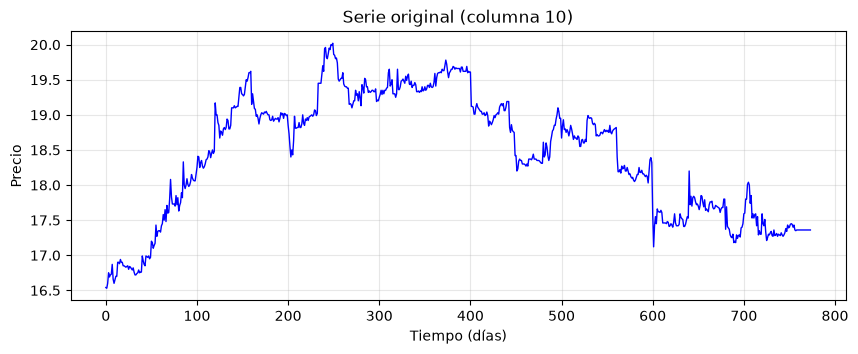

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings('ignore')

# Cargar el CSV (sin encabezado) y extraer la columna del activo
df = pd.read_csv('Datos_BMV.csv', header=None)
data = df.iloc[:, 10].values

print('Observaciones:', len(data))
print('Mínimo: %.2f | Máximo: %.2f | Último valor: %.2f' % (data.min(), data.max(), data[-1]))

plt.figure(figsize=(10, 3.5))
plt.plot(data, 'b-', lw=1)
plt.title('Serie original (columna 10)'); plt.xlabel('Tiempo (días)'); plt.ylabel('Precio'); plt.grid(alpha=.3)
plt.show()

##  Metodología

**Matriz de rezagos.** Igual que en `MLP_1.py`: la entrada son los `nrez` valores anteriores y la salida es el valor actual. Se usa el **90 % inicial** para entrenar y el **10 % final** como conjunto de prueba.

**Dos bloques de pruebas**
- **Bloque A (código base):** `activation='identity'`, datos sin escalar.
- **Bloque B (variante no lineal):** `activation='tanh'` con estandarización de entradas y salida (el escalador se ajusta solo con entrenamiento).

**Rejilla:** 6 números de rezagos (1, 3, 5, 10, 20, 30) × 8 arquitecturas × 2 bloques = **96 combinaciones**. Cada una se entrena con **5 semillas** y se promedia, porque los pesos iniciales son aleatorios.

**Métricas:** RMSE, MAE, MAPE (%) y R², en entrenamiento y prueba. Referencia: modelo ingenuo *y(t) = y(t−1)*.

**Corrección importante al código base.** En `MLP_1.py`, `A = X[:, -1:]` es el vector de entrada de la última fila de X, que predice el último dato *ya conocido*, no el siguiente. Para predecir el día futuro la entrada debe ser `[y(t), y(t−1), …, y(t−nrez+1)]`, es decir, los últimos `nrez` datos reales (`data[::-1][:nrez]`), que es lo que se usa abajo. Además, `identity` es lineal, por lo que apilar capas equivale a una sola capa lineal; por eso se añade el Bloque B.

### Modelo de referencia 

In [2]:
def build(nrez):
    """Matriz de rezagos como en MLP_1.py. Devuelve X:(N, nrez) y Y:(N,)."""
    temp = np.zeros((len(data) - nrez, nrez + 1))
    for k in range(nrez + 1):
        temp[:, k] = data[nrez - k: len(data) - k]   # col 0 = tiempo actual, demás = rezagos
    return temp[:, 1:], temp[:, 0]

def metricas(y, p):
    e = y - p
    return dict(RMSE=np.sqrt(np.mean(e**2)),
                MAE=np.mean(np.abs(e)),
                MAPE=100 * np.mean(np.abs(e / y)),
                R2=1 - np.sum(e**2) / np.sum((y - y.mean())**2))

def run(nrez, arch, act, scale, seed):
    """Entrena un MLP y devuelve predicciones y el siguiente valor."""
    X, Y = build(nrez)
    nd = int(round(0.9 * len(Y)))                      # 90 % entrenamiento
    Xtr, Ytr, Xte, Yte = X[:nd], Y[:nd], X[nd:], Y[nd:]
    xnext = data[::-1][:nrez].reshape(1, -1)           # entrada correcta para el SIGUIENTE valor
    if scale:
        sx = StandardScaler().fit(Xtr); sy = StandardScaler().fit(Ytr.reshape(-1, 1))
        f = sx.transform
        g = lambda p: sy.inverse_transform(p.reshape(-1, 1)).ravel()
        ytr_fit = sy.transform(Ytr.reshape(-1, 1)).ravel()
    else:
        f = lambda A: A; g = lambda p: p; ytr_fit = Ytr
    m = MLPRegressor(hidden_layer_sizes=arch, activation=act, solver='lbfgs',
                     max_iter=1000, random_state=seed)
    m.fit(f(Xtr), ytr_fit)
    return dict(model=m, ptr=g(m.predict(f(Xtr))), pte=g(m.predict(f(Xte))),
                pall=g(m.predict(f(X))), nxt=g(m.predict(f(xnext)))[0],
                Ytr=Ytr, Yte=Yte, Y=Y, nd=nd)

In [3]:
X1, Y1 = build(1)
nd1 = int(round(0.9 * len(Y1)))
ing_tr = metricas(Y1[:nd1], X1[:nd1, 0])
ing_te = metricas(Y1[nd1:], X1[nd1:, 0])
pd.DataFrame([ing_tr, ing_te], index=['entrenamiento', 'prueba']).round(4)

,RMSE,MAE,MAPE,R2
entrenamiento,0.1089,0.0643,0.3484,0.9833
prueba,0.0920,0.0561,0.3206,0.7248


<a id="p1-pruebas"></a>

### 2.4 Pruebas y resultados

###  Experimentos: variación de arquitectura y rezagos


In [4]:
lags  = [1, 3, 5, 10, 20, 30]
archs = [(5,), (10,), (20,), (10, 5), (20, 10), (10, 5, 2), (20, 10, 5), (50, 25, 10)]
bloques = {'A': ('identity', False), 'B': ('tanh', True)}
SEEDS = range(5)

rows = []
for b, (act, sc) in bloques.items():
    for nz in lags:
        for a in archs:
            R = []
            for s in SEEDS:
                o = run(nz, a, act, sc, s)
                r = {f'{k}_ent': v for k, v in metricas(o['Ytr'], o['ptr']).items()}
                r.update({f'{k}_prueba': v for k, v in metricas(o['Yte'], o['pte']).items()})
                r['siguiente'] = o['nxt']
                R.append(r)
            R = pd.DataFrame(R)
            nparam = sum(c.size for c in o['model'].coefs_) + sum(c.size for c in o['model'].intercepts_)
            row = dict(bloque=b, activacion=act, rezagos=nz, arquitectura=str(a),
                       capas=len(a), parametros=nparam)
            for c in R.columns:
                row[c] = R[c].mean()
            row['RMSE_prueba_desv'] = R['RMSE_prueba'].std()
            rows.append(row)
    print('Bloque', b, 'terminado')

res = pd.DataFrame(rows)
print('Combinaciones probadas:', len(res))

Bloque A terminado
Bloque B terminado
Combinaciones probadas: 96


###  Tabla comparativa (todas las combinaciones)
Promedio de 5 semillas. `siguiente` = predicción del siguiente valor.

In [5]:
cols = ['bloque', 'activacion', 'rezagos', 'arquitectura', 'parametros',
        'RMSE_ent', 'MAE_ent', 'MAPE_ent', 'R2_ent',
        'RMSE_prueba', 'MAE_prueba', 'MAPE_prueba', 'R2_prueba',
        'RMSE_prueba_desv', 'siguiente']
tabla = res[cols].round(4)
pd.set_option('display.max_rows', 200, 'display.width', 250, 'display.max_columns', 30)
tabla

,bloque,activacion,rezagos,arquitectura,parametros,RMSE_ent,MAE_ent,MAPE_ent,R2_ent,RMSE_prueba,MAE_prueba,MAPE_prueba,R2_prueba,RMSE_prueba_desv,siguiente
0,A,identity,1,"(5,)",16,0.1085,0.0654,0.3542,0.9834,0.0923,0.0579,0.3313,0.7235,0.0001,17.3733
1,A,identity,1,"(10,)",31,0.1085,0.0653,0.3539,0.9834,0.0922,0.0579,0.3308,0.7237,0.0001,17.3729
2,A,identity,1,"(20,)",61,0.1085,0.0656,0.3552,0.9834,0.0924,0.0583,0.3334,0.7227,0.0002,17.3747
3,A,identity,1,"(10, 5)",81,0.1085,0.0654,0.3545,0.9834,0.0923,0.0581,0.3320,0.7233,0.0000,17.3738
4,A,identity,1,"(20, 10)",261,0.1085,0.0654,0.3542,0.9834,0.0923,0.0579,0.3313,0.7235,0.0001,17.3733
5,A,identity,1,"(10, 5, 2)",90,0.1085,0.0654,0.3546,0.9834,0.0923,0.0581,0.3322,0.7232,0.0000,17.3739
6,A,identity,1,"(20, 10, 5)",311,0.1085,0.0654,0.3545,0.9834,0.0923,0.0581,0.3321,0.7233,0.0000,17.3739
7,A,identity,1,"(50, 25, 10)",1646,0.1085,0.0654,0.3545,0.9834,0.0923,0.0581,0.3320,0.7233,0.0000,17.3738
8,A,identity,3,"(5,)",26,0.1072,0.0646,0.3496,0.9835,0.0905,0.0558,0.3189,0.7341,0.0001,17.3727
9,A,identity,3,"(10,)",51,0.1073,0.0649,0.3514,0.9835,0.0907,0.0564,0.3224,0.7330,0.0010,17.3752


### Resumen: RMSE de prueba por rezagos y arquitectura

In [6]:
orden = [str(a) for a in archs]
for b in ['A', 'B']:
    print(f'--- Bloque {b} ({bloques[b][0]}) ---')
    pv = res[res.bloque == b].pivot(index='arquitectura', columns='rezagos', values='RMSE_prueba').loc[orden]
    display(pv.round(4))
print('Referencia modelo ingenuo (prueba): %.4f' % ing_te['RMSE'])

--- Bloque A (identity) ---


rezagos,1,3,5,10,20,30
arquitectura,,,,,,
"(5,)",0.0923,0.0905,0.0907,0.0915,0.0916,0.0953
"(10,)",0.0922,0.0907,0.0911,0.0909,0.0917,0.0909
"(20,)",0.0924,0.0905,0.0907,0.0915,0.0914,0.0932
"(10, 5)",0.0923,0.0901,0.0905,0.0906,0.0924,0.0920
"(20, 10)",0.0923,0.0907,0.0911,0.0914,0.0922,0.0954
"(10, 5, 2)",0.0923,0.0905,0.0902,0.0908,0.0920,0.0926
"(20, 10, 5)",0.0923,0.0900,0.0903,0.0911,0.0916,0.0943
"(50, 25, 10)",0.0923,0.0916,0.0912,0.0913,0.0916,0.0956


--- Bloque B (tanh) ---


rezagos,1,3,5,10,20,30
arquitectura,,,,,,
"(5,)",0.0919,0.0910,0.0953,0.0952,0.1060,0.1124
"(10,)",0.0919,0.0908,0.0921,0.1022,0.1176,0.1439
"(20,)",0.0916,0.0899,0.0958,0.1115,0.1198,0.1807
"(10, 5)",0.0920,0.0891,0.0948,0.1125,0.1399,0.1857
"(20, 10)",0.0920,0.0893,0.1041,0.1181,0.1490,0.2167
"(10, 5, 2)",0.0918,0.0902,0.0904,0.1064,0.1378,0.2245
"(20, 10, 5)",0.0920,0.0902,0.0970,0.1426,0.1651,0.3082
"(50, 25, 10)",0.0920,0.0892,0.0964,0.1523,0.1850,0.3027


Referencia modelo ingenuo (prueba): 0.0920


##  Selección de la mejor configuración y predicción del siguiente valor

In [7]:
top = res.sort_values('RMSE_prueba').head(6)[['bloque', 'rezagos', 'arquitectura', 'parametros',
                                              'RMSE_ent', 'RMSE_prueba', 'R2_prueba', 'RMSE_prueba_desv', 'siguiente']]
display(top.round(4))

mejor = res.sort_values('RMSE_prueba').iloc[0]
print('\nConfiguración seleccionada: bloque %s | %d rezagos | capas %s' % (mejor.bloque, mejor.rezagos, mejor.arquitectura))
print('RMSE prueba = %.4f | R2 prueba = %.3f | MAPE prueba = %.3f %%' % (mejor.RMSE_prueba, mejor.R2_prueba, mejor.MAPE_prueba))
print('PREDICCIÓN DEL SIGUIENTE VALOR (promedio de 5 semillas): %.3f' % mejor.siguiente)
print('Último dato real: %.2f' % data[-1])

,bloque,rezagos,arquitectura,parametros,RMSE_ent,RMSE_prueba,R2_prueba,RMSE_prueba_desv,siguiente
59,B,3,"(10, 5)",101,0.1007,0.0891,0.7423,0.0007,17.3830
63,B,3,"(50, 25, 10)",1746,0.1010,0.0892,0.7414,0.0011,17.3824
60,B,3,"(20, 10)",301,0.1010,0.0893,0.7407,0.0013,17.3829
58,B,3,"(20,)",101,0.1010,0.0899,0.7376,0.0012,17.3819
14,A,3,"(20, 10, 5)",351,0.1074,0.0900,0.7367,0.0010,17.3710
11,A,3,"(10, 5)",101,0.1073,0.0901,0.7362,0.0009,17.3711



Configuración seleccionada: bloque B | 3 rezagos | capas (10, 5)
RMSE prueba = 0.0891 | R2 prueba = 0.742 | MAPE prueba = 0.342 %
PREDICCIÓN DEL SIGUIENTE VALOR (promedio de 5 semillas): 17.383
Último dato real: 17.36


###  Gráficas de los casos representativos
Solo se grafican tres casos: la **mejor configuración**, un caso de **subajuste** y el de **mayor complejidad/rezagos** (sobreajuste). Se muestra la corrida cuya semilla queda más cerca del promedio de las 5 semillas. A la derecha, un zoom del conjunto de prueba.

In [8]:
def graficar(nombre, nrez, arch, act, sc):
    runs = [run(nrez, arch, act, sc, s) for s in SEEDS]
    rm = np.array([metricas(r['Yte'], r['pte'])['RMSE'] for r in runs])
    o = runs[int(np.argmin(np.abs(rm - rm.mean())))]          # semilla representativa
    n, nd = len(o['Y']), o['nd']; t = np.arange(1, n + 1)
    mt, me = metricas(o['Yte'], o['pte']), metricas(o['Ytr'], o['ptr'])
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1.3, 1]})
    ax[0].plot(t, o['Y'], 'b-', lw=1, label='Datos reales')
    ax[0].plot(t, o['pall'], 'r-', lw=.8, label='Simulación MLP')
    ax[0].axvline(nd + .5, color='gray', ls='--', label='Inicio de prueba (10 %)')
    ax[0].plot(n + 1, o['nxt'], 'g*', ms=13, label='Predicción siguiente: %.3f' % o['nxt'])
    ax[0].set(title='Serie completa', xlabel='Tiempo (días)', ylabel='Precio'); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
    ax[1].plot(t[nd:], o['Yte'], 'b.-', lw=1, label='Datos reales (prueba)')
    ax[1].plot(t[nd:], o['pte'], 'r.-', lw=1, label='Predicción MLP (prueba)')
    ax[1].plot(n + 1, o['nxt'], 'g*', ms=13)
    ax[1].set(title='Zoom prueba — RMSE=%.4f, R²=%.3f' % (mt['RMSE'], mt['R2']), xlabel='Tiempo (días)')
    ax[1].legend(fontsize=8); ax[1].grid(alpha=.3)
    fig.suptitle(nombre, fontweight='bold'); fig.tight_layout(); plt.show()
    return dict(caso=nombre, RMSE_ent=me['RMSE'], RMSE_prueba=mt['RMSE'], R2_prueba=mt['R2'], siguiente=o['nxt'])

casos = []

###  Mejor configuración

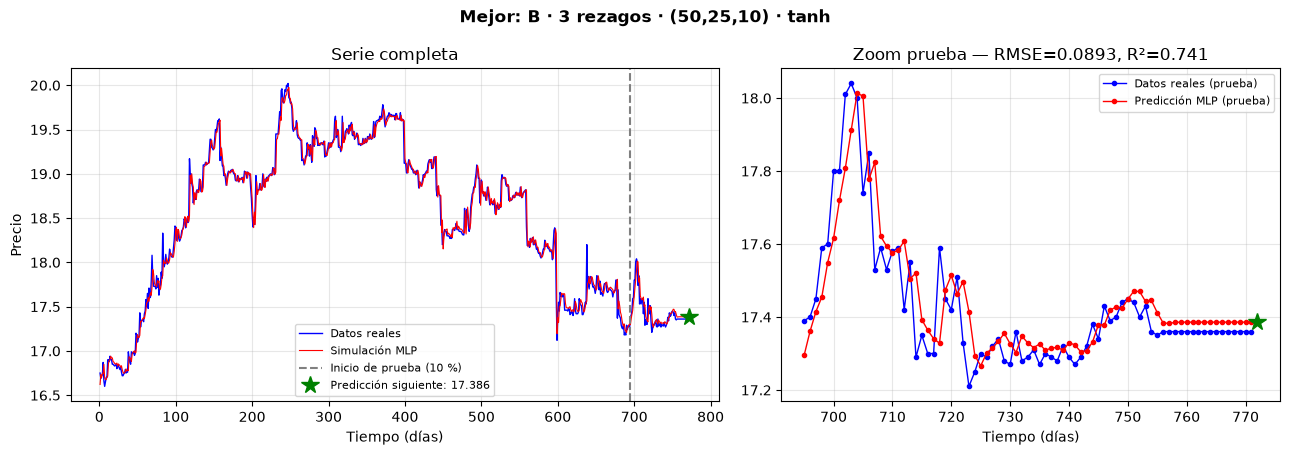

In [9]:
casos.append(graficar('Mejor: B · 3 rezagos · (50,25,10) · tanh', 3, (50, 25, 10), 'tanh', True))

###  Desempeño deficiente / subajuste

casos.append(graficar('Subajuste: A · 1 rezago · (5,) · identity', 1, (5,), 'identity', False))

###  Mayor complejidad y rezagos (sobreajuste)

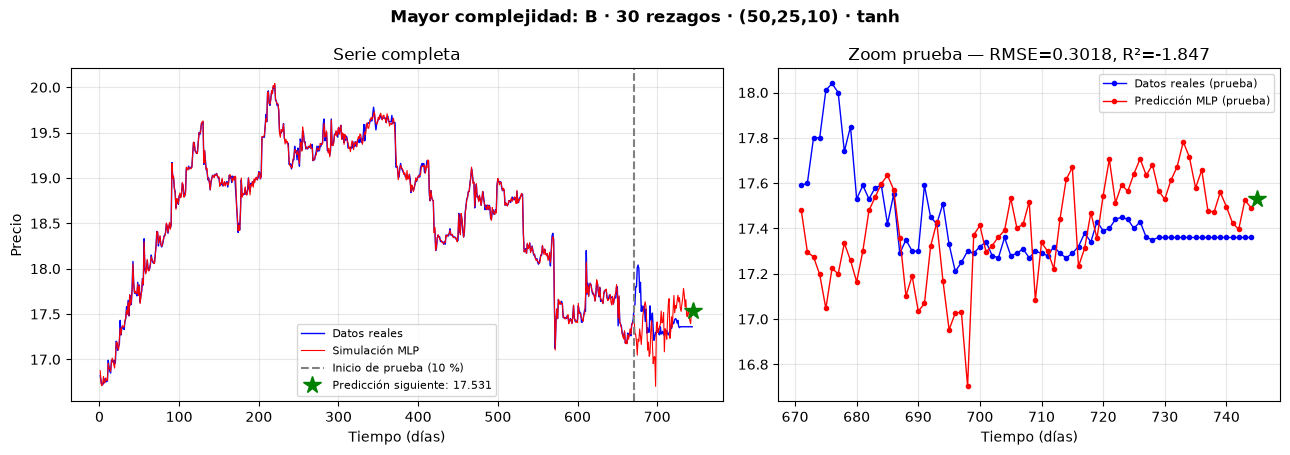

,RMSE_ent,RMSE_prueba,R2_prueba,siguiente
caso,,,,
"Mejor: B · 3 rezagos · (50,25,10) · tanh",0.1013,0.0893,0.7409,17.3859
"Mayor complejidad: B · 30 rezagos · (50,25,10) · tanh",0.0279,0.3018,-1.8469,17.5314


In [10]:
casos.append(graficar('Mayor complejidad: B · 30 rezagos · (50,25,10) · tanh', 30, (50, 25, 10), 'tanh', True))
pd.DataFrame(casos).set_index('caso').round(4)

##  Datos de apoyo para el análisis

In [11]:
print('RMSE de prueba promedio por número de rezagos')
display(res.groupby(['bloque', 'rezagos'])[['RMSE_ent', 'RMSE_prueba']].mean().round(4).unstack(0))
print('RMSE de prueba promedio por número de capas ocultas')
display(res.groupby(['bloque', 'capas'])[['RMSE_prueba']].mean().round(4).unstack(0))
print('Rango RMSE prueba  A: %.4f – %.4f | B: %.4f – %.4f' % (
      res[res.bloque=='A'].RMSE_prueba.min(), res[res.bloque=='A'].RMSE_prueba.max(),
      res[res.bloque=='B'].RMSE_prueba.min(), res[res.bloque=='B'].RMSE_prueba.max()))
k = 0
while data[-1 - k] == data[-1]:
    k += 1
print('Días finales con el mismo valor (%.2f): %d' % (data[-1], k))

RMSE de prueba promedio por número de rezagos


RMSE_ent         RMSE_prueba        
bloque         A       B           A       B
rezagos                                     
1         0.1085  0.1084      0.0923  0.0919
3         0.1074  0.1014      0.0906  0.0900
5         0.1074  0.0953      0.0907  0.0957
10        0.1068  0.0876      0.0912  0.1176
20        0.1076  0.0757      0.0918  0.1400
30        0.1086  0.0617      0.0937  0.2094

RMSE de prueba promedio por número de capas ocultas


RMSE_prueba        
bloque           A       B
capas                     
1           0.0916  0.1066
2           0.0918  0.1236
3           0.0917  0.1419

Rango RMSE prueba  A: 0.0900 – 0.0956 | B: 0.0891 – 0.3082
Días finales con el mismo valor (17.36): 16


<a id="p1-analisis"></a>

### 2.5 Análisis y conclusiones de la práctica

## Análisis comparativo

**El precio se comporta casi como un paseo aleatorio.** En el Bloque A todos los RMSE de prueba están entre 0.0900 y 0.0949 y el modelo ingenuo obtiene 0.0920. La mejor red mejora al ingenuo apenas ~3 %, una diferencia del orden de la variación entre semillas (desviaciones de 0.001 a 0.003). El pasado reciente aporta casi solo el último valor y el MLP no encuentra estructura adicional aprovechable.

**Efecto de la arquitectura.** En el Bloque A es prácticamente nulo (RMSE promedio 0.0913, 0.0917 y 0.0917 con 1, 2 y 3 capas), lo esperable en una red lineal. En el Bloque B, más capas y neuronas empeoran la prueba (0.107, 0.122 y 0.141 en promedio) porque aumentan los parámetros sin que haya más señal que aprender.

**Efecto del número de rezagos.** Pasar de 1 a 3 rezagos mejora ligeramente (A: 0.0923 → 0.0906; B: 0.0919 → 0.0901). Después, en el Bloque A el error casi no cambia y sube un poco con 30 rezagos. En el Bloque B el error de entrenamiento baja de 0.108 a 0.062 mientras el de prueba sube de 0.092 a 0.207: sobreajuste clásico, pues cada rezago extra agrega entradas y pesos que la red usa para memorizar ruido.

**Subajuste vs. sobreajuste.** El caso de subajuste (1 rezago, red lineal) falla por falta de capacidad: su error de entrenamiento (0.1085) es el más alto y coincide con el del modelo ingenuo. El caso complejo falla por exceso de capacidad: error de entrenamiento mínimo (0.040) y de prueba máximo (0.287, R² negativo). La mejor configuración está en un punto intermedio.

**Sobre las métricas.** El R² de prueba (~0.72–0.74) es menor que el de entrenamiento (>0.98) no porque los modelos predigan peor, sino porque el periodo de prueba es más estable y su varianza es pequeña. El error relativo es bajo (MAPE ≈ 0.32–0.34 %). Además, los últimos 16 datos están congelados en 17.36, lo que favorece a cualquier modelo que repita el último valor.

**Predicción del siguiente valor.** Los modelos razonables predicen entre 17.37 y 17.38, prácticamente igual al último dato. El modelo sobreajustado se aleja (17.52–17.54) sin justificación en los datos.


## Conclusión Esmer 

Con esta práctica aprendí que una red más compleja no necesariamente ofrece mejores resultados. Después de probar 96 combinaciones, las redes más sencillas tuvieron mejor desempeño y el modelo ingenuo obtuvo resultados muy similares. También comprendí la importancia de revisar el código y validar las predicciones con datos que no se utilizaron en el entrenamiento. Finalmente, considero que el MLP puede ser útil para estimar precios, pero sus resultados deben tomarse como una referencia y no como una señal directa de inversión.

<a id="practica2"></a>

## 3. Práctica 2: predicción multihorizonte con datos normalizados

<a id="p2-definicion"></a>

### 3.1 Definición del problema

Se usa el mismo activo de la Práctica 1 (columna con índice 10 de `Datos_BMV.csv`, 774 observaciones). La diferencia es que ahora la red no predice un solo día: con los **20 precios más recientes** predice los **5 días siguientes a la vez**. Es una regresión con **salida múltiple**: una sola red con **5 neuronas de salida**, una por cada horizonte.

Cambios respecto a la Práctica 1:
- **Matriz de rezagos más ancha:** se usan $n_{rez} = 20 + 5 - 1 = 24$ rezagos, es decir, 25 columnas. Las primeras 5 son las salidas y las otras 20 son las entradas. Quedan $774 - 24 = 750$ muestras: **675 de entrenamiento** (90 %) y **75 de prueba** (10 %).
- **Datos normalizados** con z-score, para que entradas y salidas queden en la misma escala, alrededor de 0.
- **Optimizador Adam** en lugar de L-BFGS, lo que permite guardar y graficar la **curva de pérdida** (`loss_curve_`).

Se busca:

1. Construir la matriz con 20 entradas y 5 salidas, y normalizarla.
2. Entrenar un MLP con capas ocultas `(10, 10, 10)`, activación `identity`, `solver='adam'` y `max_iter = 1000` (código base) con el 90 % inicial.
3. Simular toda la serie y comparar, para cada horizonte $t+1, \dots, t+5$, los valores reales contra los predichos.
4. Revisar la curva de pérdida para ver cómo y cuándo converge el entrenamiento.
5. Analizar cómo cambia el error conforme el horizonte se aleja y qué efecto tienen la normalización, la arquitectura y la activación.

<a id="p2-algoritmo"></a>

### 3.2 Descripción del algoritmo

**Orden de las columnas.** Igual que antes, la columna $k$ de `data` es la serie recorrida $k$ días. Si $\tau = t-5$ es el último día que la red conoce, las entradas son $y(\tau), \dots, y(\tau-19)$ y las salidas son $y(\tau+1), \dots, y(\tau+5)$. La **primera fila de `Y` es el horizonte más lejano** ($\tau+5$) y la quinta es el más cercano ($\tau+1$); por eso las gráficas del código base se titulan `Precio(t+{salidas - k})`.

| Columna de `data` | Contenido | Papel | Horizonte |
|---|---|---|---|
| 0 | $y(t)$ | Salida `Y[0]` | $\tau+5$ |
| 1 | $y(t-1)$ | Salida `Y[1]` | $\tau+4$ |
| 2 | $y(t-2)$ | Salida `Y[2]` | $\tau+3$ |
| 3 | $y(t-3)$ | Salida `Y[3]` | $\tau+2$ |
| 4 | $y(t-4)$ | Salida `Y[4]` | $\tau+1$ |
| 5 … 24 | $y(t-5) \dots y(t-24)$ | 20 entradas | — |

**Esquema del MLP** (capas ocultas `(10, 10, 10)`, 20 entradas y 5 salidas)

```
  Capa de entrada            Capas ocultas (identity)                  Capa de salida (5)
  (20 rezagos, z-score)

   ỹ(τ)     ──┐                                                    ┌──►  ỹ(τ+5)   Y[0]
   ỹ(τ-1)   ──┤     ┌───────────┐    ┌───────────┐    ┌───────────┐ ├──►  ỹ(τ+4)   Y[1]
   ỹ(τ-2)   ──┼───► │ 10 neur.  │──► │ 10 neur.  │──► │ 10 neur.  │─┼──►  ỹ(τ+3)   Y[2]
     ...      │     └───────────┘    └───────────┘    └───────────┘ ├──►  ỹ(τ+2)   Y[3]
   ỹ(τ-19)  ──┘                                                    └──►  ỹ(τ+1)   Y[4]
            W1 (20x10), b1     W2 (10x10), b2    W3 (10x10), b3    W4 (10x5), b4
```

Esta red tiene **485 parámetros**. Las 5 salidas comparten las mismas capas ocultas, así que la red aprende una sola representación del pasado y la usa para los 5 horizontes.

1. **Matriz de rezagos:** `data[:, k] = temp[nrez-k : N-k]` para $k = 0, \dots, 24$.
2. **Normalización z-score** de cada columna $j$:
$$\tilde{y}_j = \frac{y_j - \mu_j}{\sigma_j} \qquad\Longrightarrow\qquad y_j = \tilde{y}_j\,\sigma_j + \mu_j$$
   La segunda expresión sirve para **desnormalizar** las predicciones y medir el error en unidades de precio. Normalizar ayuda por dos razones: Adam avanza con pasos pequeños (tasa de aprendizaje de 0.001), pensados para valores de tamaño cercano a 1, y con precios cercanos a 17 la pérdida inicial es enorme y el entrenamiento tarda más; además, activaciones como `tanh` o `logistic` se **saturan** con entradas grandes (por ejemplo, $\tanh(17) \approx 1$) y dejan de aprender. En el código base $\mu$ y $\sigma$ se calculan con todas las filas; para que el 10 % de prueba no influya en el entrenamiento, conviene calcularlas solo con el 90 % de entrenamiento, como se hizo en la Práctica 1 con `StandardScaler`.
3. **Separación:** `Y` = columnas 0 a 4 (5 salidas) y `X` = columnas 5 a 24 (20 entradas); las primeras 675 filas son de entrenamiento.
4. **Propagación hacia adelante:** igual que en la Práctica 1, pero la capa de salida produce un vector de 5 valores, $\hat{\mathbf{y}} = W^{(4)}a^{(3)} + b^{(4)}$. Con `identity` la red completa sigue siendo **lineal**: cada salida es una combinación lineal de los 20 rezagos.
5. **Función de pérdida:** se promedia el error cuadrático sobre las $n$ muestras y las $m = 5$ salidas:
$$L = \frac{1}{2nm}\sum_{i=1}^{n}\sum_{j=1}^{m}\big(\tilde{y}_{ij} - \hat{\tilde{y}}_{ij}\big)^2 + \frac{\alpha}{2n}\,\lVert W \rVert_2^2$$
6. **Entrenamiento con Adam:** en cada época se revuelven las filas de entrenamiento y se dividen en lotes de hasta 200 muestras. Para cada lote se calculan los gradientes $g$ con retropropagación y cada peso se actualiza con promedios móviles del gradiente y de su cuadrado:
$$m_t = \beta_1 m_{t-1} + (1-\beta_1)\,g_t, \qquad v_t = \beta_2 v_{t-1} + (1-\beta_2)\,g_t^2$$
$$w \leftarrow w - \eta\,\frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \varepsilon}, \qquad \hat{m}_t = \frac{m_t}{1-\beta_1^t}, \quad \hat{v}_t = \frac{v_t}{1-\beta_2^t}$$
   con $\eta = 0.001$, $\beta_1 = 0.9$, $\beta_2 = 0.999$ y $\varepsilon = 10^{-8}$ (valores por defecto). Así cada peso tiene su propio tamaño de paso. La pérdida de cada época se guarda en `loss_curve_`, y el entrenamiento se detiene si la pérdida no mejora más de $10^{-4}$ durante 10 épocas seguidas o al llegar a 1000 épocas.
7. **Simulación y evaluación:** se predicen las 5 salidas para toda la serie, se desnormalizan y, para cada horizonte, se grafican los valores reales contra los simulados y se calculan las métricas de error en entrenamiento y prueba (RMSE, MAE, MAPE y $R^2$, como en la Práctica 1).
8. **Predicción futura:** con los últimos 20 datos reales normalizados, $[\,\tilde{y}(T), \dots, \tilde{y}(T-19)\,]$, la red entrega $\hat{y}(T+1), \dots, \hat{y}(T+5)$, que se desnormalizan para obtener precios.

**Pseudocódigo**
```
INICIO
    temp <- columna con índice 10 de Datos_BMV.csv      // 774 precios
    salidas <- 5
    nrez <- 20 + salidas - 1                             // 24
    PARA k = 0 HASTA nrez HACER
        data[:, k] <- temp[nrez-k : N-k]                 // col 0 = y(t), col k = y(t-k)
    FIN PARA
    μ, σ <- media y desviación estándar de cada columna (de preferencia, solo con entrenamiento)
    data <- (data - μ) / σ                               // normalización z-score
    Y <- columnas 0..4  (5 salidas)         X <- columnas 5..24  (20 entradas)
    ndat <- round(0.9 * 750)                             // 675
    (Xtrain, Ytrain) <- primeras ndat filas
    red <- MLPRegressor((10, 10, 10), activation = 'identity', solver = 'adam', max_iter = 1000)
    PARA época = 1 HASTA max_iter HACER                  // red.fit(Xtrain, Ytrain)
        Revolver las filas de entrenamiento y dividirlas en lotes de 200
        PARA cada lote HACER
            Ŷ <- propagación hacia adelante del lote     // 5 salidas por fila
            L <- promedio de (Y - Ŷ)² / 2 + penalización L2
            gradientes <- retropropagación
            actualizar W y b con Adam
        FIN PARA
        Guardar L en loss_curve_
        SI L no mejora más de 1e-4 en 10 épocas seguidas ENTONCES terminar
    FIN PARA
    Yg <- red.predict(X)                                 // 5 predicciones por fila
    Desnormalizar: y <- ỹ * σ + μ
    PARA cada horizonte h = 1..5 HACER
        Graficar real vs. simulado y calcular el error en entrenamiento y prueba
    FIN PARA
    Graficar loss_curve_
    x_sig <- últimos 20 datos reales normalizados        // [y(T), ..., y(T-19)]
    ŷ(T+1..T+5) <- red.predict(x_sig), desnormalizado
FIN
```

<a id="p2-implementacion"></a>

### 3.3 Implementación

*Sección por completar por el equipo.*

<a id="p2-pruebas"></a>

### 3.4 Pruebas y resultados

*Sección por completar por el equipo.*

<a id="p2-analisis"></a>

### 3.5 Análisis y conclusiones de la práctica

*Sección por completar por el equipo.*

<a id="conclusiones"></a>

## 4. Conclusiones

<a id="conclusiones-personales"></a>

### 4.1 Conclusiones personales

**Dayanni**

Me tocó preparar la estructura del reporte y el marco teórico de las dos prácticas, y eso me obligó a entender bien qué hace el código antes de ver los resultados. Lo que más me ayudó fue ver cómo una serie de tiempo, que en principio no tiene "entradas" y "salidas", se vuelve un problema supervisado con la matriz de rezagos: cada fila es un pedazo del pasado y la respuesta correcta es el precio que sigue. También aprendí a revisar con cuidado el orden de las columnas: en la Práctica 2 la primera salida es el horizonte más lejano y no el más cercano, y en la Práctica 1 la entrada que usaba el código base para la predicción futura en realidad estimaba el último dato que ya conocíamos. Otra cosa que me quedó clara es que, con la activación `identity`, la red sigue siendo lineal aunque tenga varias capas, así que agregar capas no le da más capacidad; para eso se necesita una activación no lineal y, en ese caso, normalizar los datos para que no se sature y para que Adam avance con pasos adecuados. Finalmente, ver en la Práctica 1 que la mejor red apenas mejoró al modelo ingenuo me hizo entender que un MLP no adivina el futuro: describe bien el comportamiento reciente del precio, pero siempre hay que compararlo con un modelo sencillo antes de confiar en sus predicciones.

<a id="conclusiones-generales"></a>

### 4.2 Conclusiones generales

*Sección por completar por el equipo.*